In [1]:
import mne

In [2]:
raw = mne.io.read_raw_edf("P2_T1.edf", preload=True)

Extracting EDF parameters from C:\Users\Suyash\Documents\Python\P2_T1.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 55039  =      0.000 ...   214.996 secs...


In [3]:
# Define the channel names
channels_8 = ["AF3","F7","F3","FC5","T7","P7","O1","O2","P8","T8","FC6","F4","F8","AF4"]
# channels_8= ["CQ_P7","CQ_O1","CQ_P8","EQ_SampleRateQua"]
#Create new raw objects from the subset selections for further analysis
raw.pick(channels_8) 

<RawEDF | P2_T1.edf, 14 x 55040 (215.0 s), ~5.9 MiB, data loaded>

In [4]:
emotiv_montage = mne.channels.make_standard_montage("standard_1020")

In [5]:
emotiv_montage.get_positions()["ch_pos"]

OrderedDict([('Fp1', array([-0.0294367,  0.0839171, -0.00699  ])),
             ('Fpz', array([ 0.0001123,  0.088247 , -0.001713 ])),
             ('Fp2', array([ 0.0298723,  0.0848959, -0.00708  ])),
             ('AF9', array([-0.0489708,  0.0640872, -0.047683 ])),
             ('AF7', array([-0.0548397,  0.0685722, -0.01059  ])),
             ('AF5', array([-0.0454307,  0.0728622,  0.005978 ])),
             ('AF3', array([-0.0337007,  0.0768371,  0.021227 ])),
             ('AF1', array([-0.0184717,  0.0799041,  0.032752 ])),
             ('AFz', array([0.0002313, 0.080771 , 0.035417 ])),
             ('AF2', array([0.0198203, 0.0803019, 0.032764 ])),
             ('AF4', array([0.0357123, 0.0777259, 0.021956 ])),
             ('AF6', array([0.0465843, 0.0738078, 0.006034 ])),
             ('AF8', array([ 0.0557433,  0.0696568, -0.010755 ])),
             ('AF10', array([ 0.0504352,  0.0638698, -0.048005 ])),
             ('F9', array([-0.0701019,  0.0416523, -0.049952 ])),
       

In [6]:
positions = emotiv_montage.get_positions()["ch_pos"]
selected_positions = {ch: pos for ch, pos in positions.items() if ch in channels_8}
selected_positions

{'AF3': array([-0.0337007,  0.0768371,  0.021227 ]),
 'AF4': array([0.0357123, 0.0777259, 0.021956 ]),
 'F7': array([-0.0702629,  0.0424743, -0.01142  ]),
 'F3': array([-0.0502438,  0.0531112,  0.042192 ]),
 'F4': array([0.0518362, 0.0543048, 0.040814 ]),
 'F8': array([ 0.0730431,  0.0444217, -0.012    ]),
 'FC5': array([-0.0772149,  0.0186433,  0.02446  ]),
 'FC6': array([0.0795341, 0.0199357, 0.024438 ]),
 'T7': array([-0.0841611, -0.0160187, -0.009346 ]),
 'T8': array([ 0.0850799, -0.0150203, -0.00949  ]),
 'P7': array([-0.0724343, -0.0734527, -0.002487 ]),
 'P8': array([ 0.0730557, -0.0730683, -0.00254  ]),
 'O1': array([-0.0294134, -0.112449 ,  0.008839 ]),
 'O2': array([ 0.0298426, -0.112156 ,  0.0088   ])}

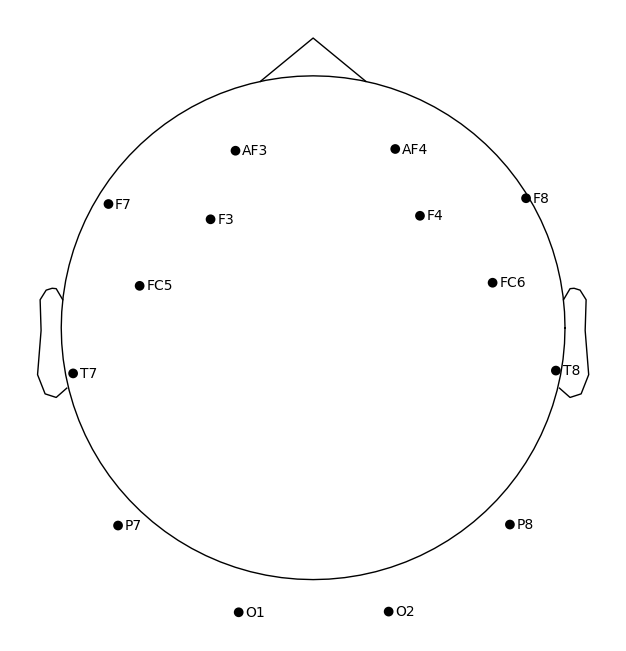

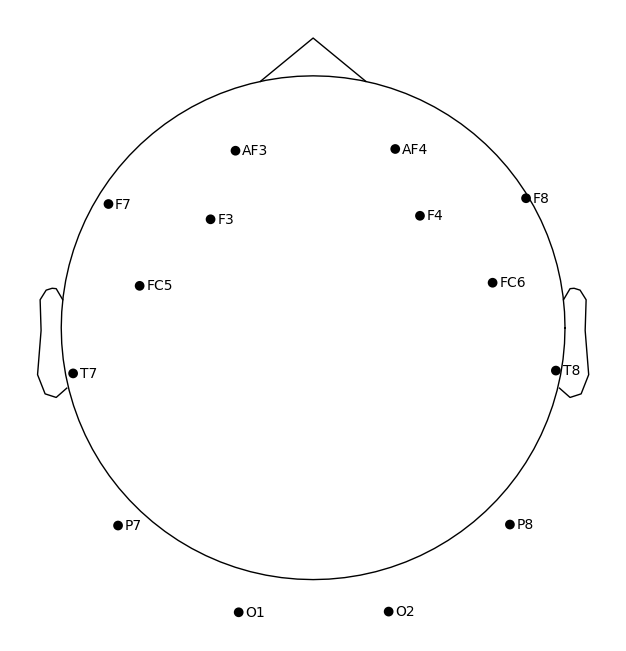

In [7]:
emotiv_montage_8 = mne.channels.make_dig_montage(ch_pos= selected_positions, coord_frame='head')

# Set the montage to the raw object to obtain digitaization points
raw.set_montage(emotiv_montage_8)

raw.plot_sensors(show_names=True)

In [ ]:
# Apply high-pass filter to remove slow drifts (e.g., cut-off at 1 Hz)
raw.filter(l_freq=1, h_freq=None, fir_design='firwin')

In [8]:
from mne.preprocessing import ICA

# Create an ICA object
ica_8 = ICA(n_components=14, random_state=97, max_iter=15000)

# Additional amplitude-based criteria
reject_criteria = dict(eeg=200e-6)  

# Fit the ICA model to raw the data
ica_8.fit(raw, reject=reject_criteria, flat=None, reject_by_annotation=True)

Fitting ICA to data using 14 channels (please be patient, this may take a while)
    Rejecting  epoch based on EEG : ['F7', 'F3', 'T7', 'T8', 'FC6', 'F4', 'F8', 'AF4']
Artifact detected in [0, 512]
    Rejecting  epoch based on EEG : ['T8', 'AF4']
Artifact detected in [512, 1024]
    Rejecting  epoch based on EEG : ['AF4']
Artifact detected in [1024, 1536]
    Rejecting  epoch based on EEG : ['AF4']
Artifact detected in [1536, 2048]
    Rejecting  epoch based on EEG : ['AF4']
Artifact detected in [2048, 2560]
    Rejecting  epoch based on EEG : ['O2', 'P8', 'T8', 'F4']
Artifact detected in [2560, 3072]
    Rejecting  epoch based on EEG : ['O2', 'P8', 'T8', 'FC6', 'F4']
Artifact detected in [3072, 3584]
    Rejecting  epoch based on EEG : ['O2', 'P8', 'T8']
Artifact detected in [3584, 4096]
    Rejecting  epoch based on EEG : ['O2', 'P8', 'T8']
Artifact detected in [4096, 4608]
    Rejecting  epoch based on EEG : ['P8']
Artifact detected in [4608, 5120]
    Rejecting  epoch based on EEG

C:\Users\Suyash\AppData\Local\Temp\ipykernel_4536\4090658247.py:10: RuntimeWarning: The data has not been high-pass filtered. For good ICA performance, it should be high-pass filtered (e.g., with a 1.0 Hz lower bound) before fitting ICA.
  ica_8.fit(raw, reject=reject_criteria, flat=None, reject_by_annotation=True)


    Rejecting  epoch based on EEG : ['AF3', 'F7', 'F3', 'FC5', 'T7', 'P7', 'O1', 'O2', 'FC6', 'F4', 'F8', 'AF4']
Artifact detected in [20992, 21504]
    Rejecting  epoch based on EEG : ['P7', 'T8']
Artifact detected in [21504, 22016]
    Rejecting  epoch based on EEG : ['P7', 'T8']
Artifact detected in [23552, 24064]
    Rejecting  epoch based on EEG : ['AF3', 'F7', 'F3', 'FC5', 'T7', 'O1', 'T8', 'FC6', 'F4', 'F8', 'AF4']
Artifact detected in [24064, 24576]
    Rejecting  epoch based on EEG : ['AF4']
Artifact detected in [27648, 28160]
    Rejecting  epoch based on EEG : ['AF4']
Artifact detected in [28160, 28672]
    Rejecting  epoch based on EEG : ['T7', 'F8', 'AF4']
Artifact detected in [28672, 29184]
    Rejecting  epoch based on EEG : ['P7']
Artifact detected in [29696, 30208]
    Rejecting  epoch based on EEG : ['AF3', 'T7', 'F4', 'AF4']
Artifact detected in [30208, 30720]
    Rejecting  epoch based on EEG : ['T7', 'F4', 'AF4']
Artifact detected in [30720, 31232]
    Rejecting  e

Method,fastica
Fit parameters,algorithm=parallelfun=logcoshfun_args=Nonemax_iter=15000
Fit,42 iterations on raw data (21504 samples)
ICA components,14
Available PCA components,14
Channel types,eeg
ICA components marked for exclusion,—


In [ ]:
ica_8.plot_sources(raw)

In [ ]:
ica_8.plot_components()

In [ ]:
### ------------Plotting individual ICA components Spectral Density -------------###
import numpy as np
import matplotlib.pyplot as plt
# Define frequency range
frequencies = np.logspace(0, 2, 100)

# Get a colormap
cmap = plt.get_cmap('plasma')

# Create a figure and axis
fig, ax = plt.subplots()

# Plot PSD of individual ICA components with distinct colors
for idx in range(ica_8.n_components_):
    color = cmap(idx / ica_8.n_components_)  # Use the colormap to get a distinct color
    psd, freqs = plt.psd(ica_8.get_sources(raw).get_data()[idx], NFFT=1024, Fs=raw.info['sfreq'], noverlap=512, label=f'Component {idx}', color=color)

# Add legend
plt.legend()

# Set plot labels
plt.title('Power Spectral Density of ICA Components')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power/Frequency (dB/Hz)')

# Zoom out after all components have been plotted
plt.autoscale()

# Enable hover tooltips
cursor = mplcursors.cursor(hover=True)

# Define the hover tooltip format
@cursor.connect("add")
def on_hover(sel):
    idx = int(sel.artist.get_label().split()[-1])  # Extract the component index from the label
    sel.annotation.set_text(f'Component {idx}')

# Display the plot
plt.show()